# AQI Prediction for Indian Cities: Preprocessing, Modeling and Evaluation

**What this notebook does:** it turns the raw data into a model that forecasts **tomorrow's AQI**, and proves the model is good with a fair, leak-free evaluation. Every decision here comes from the findings in `01_eda.ipynb`.

**How to study it:** each section has a **What and why** note, the code, and an **Insight** that explains the result in plain language. Section 13 lists likely viva questions with short answers.

Sections:
1. Setup
2. Load the data and create the target (tomorrow's AQI)
3. Clean the data (bad CO rows, AQI cap)
4. Split into train and test by date
5. Build the features
6. Pipelines and time-based cross-validation
7. Baseline and model comparison with cross-validation
8. Hyperparameter tuning
9. Final evaluation on the test set
10. Interpretation: which features drive predictions
11. Error analysis: where and why the model fails
12. Save the model and results for the app
13. Conclusion, limitations and viva preparation

## 1. Setup

**What and why:** we import the libraries and the project's own helper code from `src/`. The helpers (`src/data.py`, `src/features.py`) are shared with the Streamlit app, so the app prepares inputs **exactly** like training did. `RANDOM_STATE = 42` fixes every random choice, so running the notebook again gives the same results (reproducibility).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

from src.config import (FEATURE_COLS, FEATURE_COLS_PATH, FILL_VALUES_PATH, METRICS_PATH,
                        MODEL_PATH, POLLUTANTS, RANDOM_STATE, SPLIT_DATE, TARGET)
from src.data import add_target, load_raw, remove_bad_rows, time_split
from src.features import AQI_BINS, AQI_LABELS, add_date_features

sns.set_theme(style="whitegrid")
np.random.seed(RANDOM_STATE)

## 2. Load the data and create the target

**What and why:** the dataset gives today's AQI, but we want to predict **tomorrow's**. `add_target()` (in `src/data.py`) sorts rows by city and date, then shifts each city's AQI up by one row, so each row's `AQI_tomorrow` is the same city's AQI on the next day.

If the next row is **not exactly one day later** (a gap in the data), the target is set to missing, so the model never learns from a "tomorrow" that is really next week.

In [2]:
df = load_raw()
df = add_target(df)

print(df.shape)
print(df[["City", "Date", "AQI", TARGET]].query("City == 'Delhi'").head(6))
print("Rows with a valid tomorrow target:", df[TARGET].notna().sum())

(29531, 17)
        City       Date    AQI  AQI_tomorrow
10229  Delhi 2015-01-01  472.0         454.0
10230  Delhi 2015-01-02  454.0         143.0
10231  Delhi 2015-01-03  143.0         319.0
10232  Delhi 2015-01-04  319.0         325.0
10233  Delhi 2015-01-05  325.0         318.0
10234  Delhi 2015-01-06  318.0         353.0
Rows with a valid tomorrow target: 24849


**Insight:** For Delhi, each row's `AQI_tomorrow` equals the next row's `AQI`, which confirms the shift works. 24,849 of 29,531 rows have a valid target. The rest are either the last day of a city's record, followed by a gap, or have no AQI the next day, and they are dropped before training.

## 3. Clean the data

**What and why:** EDA showed that Ahmedabad's CO column is a copy of NO in 1,317 rows, and that every Ahmedabad AQI above 500 is in those rows. `remove_bad_rows()`:
- **drops** those copied-CO rows, because their pollutant values are wrong, and
- **caps** AQI and AQI_tomorrow at **500**, the official maximum of the Indian AQI scale.

This is deliberate outlier treatment based on evidence, not automatic removal of "big numbers".

In [3]:
rows_before = len(df)
df = remove_bad_rows(df)
print("Rows dropped (copied CO):", rows_before - len(df))
print(df.shape)
print(df["AQI"].describe().round(1))

Rows dropped (copied CO): 1317
(28214, 17)
count    23604.0
mean       149.7
std        100.7
min         13.0
25%         79.0
50%        113.0
75%        187.0
max        500.0
Name: AQI, dtype: float64


**Insight:** Dropping the 1,317 copied-CO rows leaves 28,214 rows. After capping, the maximum AQI is 500 and the mean falls from about 166 to 150, so the faulty Ahmedabad values no longer distort what the model learns.

## 4. Split into train and test by date

**What and why:** this is time-series data, so a **random** split would leak the future: the model could train on March 2019 and be tested on February 2019. Instead we train on **2015 to 2018** and test on **2019 to mid-2020**, which copies real forecasting, where only the past is known.

The split happens **before** anything is fitted (no medians, scalers or models yet), so no information from the test years can leak into training.

In [4]:
train, test = time_split(df, SPLIT_DATE)

print("Train rows:", len(train), "| Test rows:", len(test))
print("Train dates:", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test dates:", test["Date"].min().date(), "to", test["Date"].max().date())

Train rows: 12575 | Test rows: 11027
Train dates: 2015-01-01 to 2018-12-31
Test dates: 2019-01-01 to 2020-06-30


**Insight:** 12,575 training rows (2015 to 2018) and 11,027 test rows (2019 to June 2020). Both sets are sorted by date, which the time-based cross-validation in section 6 needs.

## 5. Build the features

**What and why:** EDA showed a strong seasonal cycle (winter smog, monsoon rain), so `add_date_features()` adds:
- `month` (1 to 12),
- `day_of_week` (0 = Monday to 6 = Sunday),
- four 0/1 **season** columns (one-hot encoding), because a model cannot use the text "winter" directly.

The season columns come from a fixed list, so train, test and the app always get identical columns.

**Missing values are not filled here.** They are filled inside the model Pipeline (section 6), so the medians are learned from training data only, and inside cross-validation from each training fold only.

In [5]:
train = add_date_features(train)
test = add_date_features(test)

X_train, y_train = train[FEATURE_COLS], train[TARGET]
X_test, y_test = test[FEATURE_COLS], test[TARGET]

print("Features:", FEATURE_COLS)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nMissing values per pollutant in X_train:")
print(X_train[POLLUTANTS].isna().sum())

# Medians from the training data only. The app uses these to pre-fill its form.
fill_values = X_train[POLLUTANTS].median()
print("\nTraining medians:")
print(fill_values)

Features: ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3', 'month', 'day_of_week', 'season_monsoon', 'season_post_monsoon', 'season_summer', 'season_winter']
X_train: (12575, 13) | X_test: (11027, 13)

Missing values per pollutant in X_train:
PM2.5     484
PM10     4939
NO2       141
SO2       325
CO        147
O3        397
NH3      3998
dtype: int64

Training medians:
PM2.5     57.150
PM10     108.635
NO2       24.975
SO2        7.970
CO         0.970
O3        31.210
NH3       21.180
dtype: float64


**Insight:** The model uses 13 features: 7 pollutant readings, month, day of week and 4 season columns. The training data still has missing pollutant values, mostly NH3 and PM10, which the Pipeline will fill. City is not a feature: the model learns from the pollution readings themselves, so it can also be used for a city it has never seen.

## 6. Pipelines and time-based cross-validation

**What and why:**

**Pipeline.** A scikit-learn `Pipeline` chains the preprocessing and the model into one object:
`SimpleImputer(median)` → (`StandardScaler` for Linear Regression only) → model.
This guarantees the imputer is fitted only on whatever data the model is trained on, which prevents leakage. It also means the saved file contains preprocessing **and** model together.

**Cross-validation.** One train/test split can be lucky or unlucky. `TimeSeriesSplit(n_splits=5)` creates 5 rounds inside the training data. Each round trains on earlier dates and validates on the dates that follow, so the future never leaks into the past. We report the average score across the 5 rounds and its spread (std). The test set stays untouched until section 9.

**Why MAE is the main metric:** it is in AQI points, so it is easy to explain ("on average the forecast is off by X points"), and it is not dominated by a few extreme days. RMSE is also reported, because it punishes large misses more, and R² shows the share of the variation explained.

In [6]:
def make_pipeline(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

tscv = TimeSeriesSplit(n_splits=5)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

for i, (tr_idx, va_idx) in enumerate(tscv.split(X_train), start=1):
    print(f"Fold {i}: train {train['Date'].iloc[tr_idx].min().date()} to {train['Date'].iloc[tr_idx].max().date()}"
          f" | validate {train['Date'].iloc[va_idx].min().date()} to {train['Date'].iloc[va_idx].max().date()}")

Fold 1: train 2015-01-01 to 2016-03-27 | validate 2016-03-27 to 2017-01-22
Fold 2: train 2015-01-01 to 2017-01-22 | validate 2017-01-22 to 2017-10-08
Fold 3: train 2015-01-01 to 2017-10-08 | validate 2017-10-08 to 2018-03-29
Fold 4: train 2015-01-01 to 2018-03-29 | validate 2018-03-29 to 2018-08-16
Fold 5: train 2015-01-01 to 2018-08-16 | validate 2018-08-16 to 2018-12-31


**Insight:** Each fold trains only on dates **before** its validation dates, and the training window grows with every fold, just like a real forecaster gaining more history over time.

## 7. Baseline and model comparison with cross-validation

**What and why:** the **baseline** (`DummyRegressor`) always predicts the training average and ignores every input. Any real model must beat it clearly, otherwise it has learned nothing useful. We then compare four common regression models, from simplest to most flexible:

| Model | Idea |
|---|---|
| Linear Regression | AQI as a weighted sum of the inputs (straight-line relationships) |
| Decision Tree | A flowchart of yes/no questions on the inputs |
| Random Forest | Many decision trees on random samples, averaged |
| Gradient Boosting | Trees built one after another, each fixing the previous trees' errors |

In [7]:
candidates = {
    "Baseline (mean)": make_pipeline(DummyRegressor(strategy="mean")),
    "Linear Regression": make_pipeline(LinearRegression(), scale=True),
    "Decision Tree": make_pipeline(DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(RandomForestRegressor(n_estimators=200, max_depth=12,
                                                         random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
}

def cv_summary(name, pipe):
    scores = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=scoring)
    return {
        "Model": name,
        "CV MAE": -scores["test_MAE"].mean(),
        "CV MAE std": scores["test_MAE"].std(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean(),
    }

cv_rows = [cv_summary(name, pipe) for name, pipe in candidates.items()]
cv_df = pd.DataFrame(cv_rows).sort_values("CV MAE").round(3)
print(cv_df.to_string(index=False))

            Model  CV MAE  CV MAE std  CV RMSE  CV R2
Gradient Boosting  29.369       5.591   43.021  0.817
    Random Forest  29.733       6.052   42.816  0.816
    Decision Tree  33.230       6.061   49.682  0.754
Linear Regression  38.960       7.694   51.494  0.740
  Baseline (mean)  95.909       6.857  111.253 -0.273


**Insight:** All four models beat the baseline by a huge margin (baseline CV MAE 95.9). Gradient Boosting (29.4) and Random Forest (29.7) are best, the Decision Tree is behind (33.2), and Linear Regression is worst (39.0). This tells us the relationship between pollutants and tomorrow's AQI is **not a straight line**: tree models can capture effects such as "AQI rises much faster once PM2.5 is high". The std of about 5 to 8 points shows that some periods are harder to forecast than others.

CV errors are higher than the test errors in section 9 because the early folds train on only one or two years of data, so these numbers are for **comparing** models, not for reporting final accuracy.

## 8. Hyperparameter tuning

**What and why:** every model has settings (hyperparameters) such as the number of trees or the tree depth. Instead of guessing them, we search for good values using the **same time-based cross-validation**, so tuning never sees the test set.
- `GridSearchCV` tries **every** combination. It is fine for the Decision Tree, which has a small grid and trains fast.
- `RandomizedSearchCV` tries a **random sample** of combinations. It is much faster for Random Forest and Gradient Boosting, where the full grid would take hours.

`random_state` is fixed so the search picks the same combinations every run.

In [8]:
dt_search = GridSearchCV(
    make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    param_grid={
        "model__max_depth": [4, 6, 8, 10, 12],
        "model__min_samples_leaf": [1, 10, 30, 60],
    },
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1,
)

rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
    param_distributions={
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [8, 12, 16, None],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__max_features": [0.5, 0.8, 1.0],
    },
    n_iter=8, cv=tscv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, n_jobs=-1,
)

gb_search = RandomizedSearchCV(
    make_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions={
        "model__n_estimators": [100, 200, 300, 400],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__min_samples_leaf": [1, 5, 20, 50],
        "model__subsample": [0.7, 0.85, 1.0],
    },
    n_iter=12, cv=tscv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, n_jobs=-1,
)

searches = {
    "Decision Tree (tuned)": dt_search,
    "Random Forest (tuned)": rf_search,
    "Gradient Boosting (tuned)": gb_search,
}
best_params = {}
for name, search in searches.items():
    search.fit(X_train, y_train)
    best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name}: CV MAE {-search.best_score_:.3f}")
    print("   best settings:", best_params[name])

Decision Tree (tuned): CV MAE 31.473
   best settings: {'max_depth': 6, 'min_samples_leaf': 30}


Random Forest (tuned): CV MAE 28.763
   best settings: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.8, 'max_depth': 8}


Gradient Boosting (tuned): CV MAE 28.690
   best settings: {'subsample': 0.85, 'n_estimators': 400, 'min_samples_leaf': 20, 'max_depth': 3, 'learning_rate': 0.03}


**Insight:** Tuning helped every tree model. The best Gradient Boosting uses **many small trees** (400 trees, depth 3) with a **slow learning rate** (0.03), and each tree sees 85% of the rows (`subsample=0.85`). Learning slowly with many simple trees usually generalises better than a few big trees. `min_samples_leaf=20` stops trees from memorising single unusual days. The tuned Random Forest also prefers shallower trees (depth 8) and larger leaves (10 rows), which again reduces overfitting.

### 8.1 Choosing the final model

**What and why:** we compare the default and tuned versions **by cross-validated MAE** and pick the lowest. The choice is made on training data only. The test set is used once, afterwards, to report the final score.

In [9]:
for name, search in searches.items():
    candidates[name] = search.best_estimator_
    cv_rows.append(cv_summary(name, search.best_estimator_))

cv_df = pd.DataFrame(cv_rows).sort_values("CV MAE").reset_index(drop=True).round(3)
print(cv_df.to_string(index=False))

best_name = cv_df.loc[cv_df["Model"] != "Baseline (mean)", "Model"].iloc[0]
print("\nChosen model:", best_name)

                    Model  CV MAE  CV MAE std  CV RMSE  CV R2
Gradient Boosting (tuned)  28.690       5.050   41.923  0.825
    Random Forest (tuned)  28.763       6.034   41.660  0.828
        Gradient Boosting  29.369       5.591   43.021  0.817
            Random Forest  29.733       6.052   42.816  0.816
    Decision Tree (tuned)  31.473       4.899   45.252  0.794
            Decision Tree  33.230       6.061   49.682  0.754
        Linear Regression  38.960       7.694   51.494  0.740
          Baseline (mean)  95.909       6.857  111.253 -0.273

Chosen model: Gradient Boosting (tuned)


**Insight:** Tuned Gradient Boosting has the lowest cross-validated MAE (28.69), just ahead of tuned Random Forest (28.76), and also the lowest spread between folds (std 5.05), so it is both accurate and stable. It is chosen as the final model. The two are very close, so either would be a defensible choice.

## 9. Final evaluation on the test set (2019 to 2020)

**What and why:** now, and only now, every candidate is trained on the **full** training set (2015 to 2018) and scored **once** on the untouched test years. This is the honest estimate of how the model would do on future data.

In [10]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

test_rows = []
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    test_rows.append({"Model": name, **evaluate(y_test, pipe.predict(X_test))})

test_df = pd.DataFrame(test_rows).sort_values("MAE").reset_index(drop=True)
baseline_mae = test_df.loc[test_df["Model"] == "Baseline (mean)", "MAE"].iloc[0]
test_df["MAE vs baseline"] = ((1 - test_df["MAE"] / baseline_mae) * 100).round(1).astype(str) + "% lower"
print(test_df.round(3).to_string(index=False))

best_model = candidates[best_name]
y_pred = best_model.predict(X_test)
best_test = evaluate(y_test, y_pred)
print(f"\nChosen model ({best_name}) on the test set: "
      f"MAE {best_test['MAE']:.2f} | RMSE {best_test['RMSE']:.2f} | R2 {best_test['R2']:.3f}")

                    Model    MAE   RMSE     R2 MAE vs baseline
Gradient Boosting (tuned) 19.083 28.431  0.880     76.8% lower
    Random Forest (tuned) 19.185 28.588  0.879     76.7% lower
        Gradient Boosting 19.277 28.705  0.878     76.5% lower
            Random Forest 19.476 29.132  0.874     76.3% lower
            Decision Tree 21.164 31.525  0.853     74.2% lower
    Decision Tree (tuned) 21.710 31.567  0.852     73.6% lower
        Linear Regression 26.186 35.011  0.818     68.1% lower
          Baseline (mean) 82.165 93.705 -0.301      0.0% lower

Chosen model (Gradient Boosting (tuned)) on the test set: MAE 19.08 | RMSE 28.43 | R2 0.880


**Insight:** On the unseen 2019-2020 data, tuned Gradient Boosting reaches **MAE 19.1, RMSE 28.4 and R² 0.880**: on average the forecast is off by about 19 AQI points, and it explains 88% of the day-to-day variation. That is a **77% lower error than the baseline** (MAE 82.2). The ranking matches cross-validation, which confirms the choice was not luck. Tuning improved Gradient Boosting only slightly (19.28 → 19.08), which is normal: the default settings were already reasonable. (The tuned Decision Tree is slightly worse on test than the default one, a reminder that CV and test can disagree a little for weaker models.)

**Why MAE is the primary metric:** a user understands "about 19 points off" directly, and MAE is not dominated by the few extreme days. RMSE (28.4) is clearly higher than MAE, which shows that a minority of days have large errors. Those days are examined in section 11.

## 10. Interpretation: which features drive the predictions?

**What and why:** a model should be explainable. **Permutation importance** shuffles one feature at a time on the test set and measures how much the MAE gets worse. A big increase means the model relies heavily on that feature. It works for any model and uses unseen data, so it is more trustworthy than a model's built-in importance.

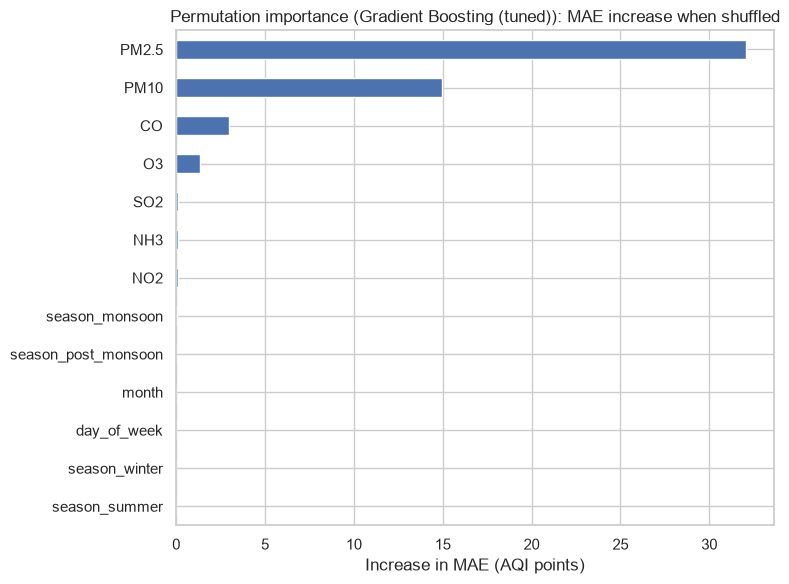

PM2.5                  32.04
PM10                   14.99
CO                      2.98
O3                      1.33
SO2                     0.12
NH3                     0.10
NO2                     0.10
season_monsoon          0.05
season_post_monsoon     0.01
month                   0.01
day_of_week             0.01
season_winter           0.00
season_summer           0.00
dtype: float64


In [11]:
perm = permutation_importance(best_model, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values()

importance.plot(kind="barh", figsize=(8, 6),
                title=f"Permutation importance ({best_name}): MAE increase when shuffled")
plt.xlabel("Increase in MAE (AQI points)")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(2))

**Insight:** **PM2.5 dominates**: shuffling it makes the MAE about 32 points worse. **PM10** is second (about 15). CO and O3 add a little, and the other gases and all date features add almost nothing. This matches how AQI is defined in India: the day's AQI is set by the worst pollutant, which is almost always particulate matter. Date features matter little because today's PM2.5 already carries the seasonal signal: winter days already have high PM2.5. In plain language: **if today's dust and smoke levels are high, tomorrow's air will very likely be bad too.**

## 11. Error analysis: where and why does the model fail?

**What and why:** an overall MAE hides where the model struggles. We break the test errors down by **city**, **season**, **actual AQI category** and **month**, and look at whether the model tends to predict too high or too low (bias = average of predicted minus actual).

In [12]:
analysis = test[["City", "Date"]].copy()
analysis["actual"] = y_test.values
analysis["predicted"] = y_pred
analysis["error"] = analysis["predicted"] - analysis["actual"]
analysis["abs_error"] = analysis["error"].abs()
analysis["season"] = test[[c for c in FEATURE_COLS if c.startswith("season_")]].idxmax(axis=1).str.replace("season_", "")
analysis["category"] = pd.cut(analysis["actual"], bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True)

by_city = analysis.groupby("City")["abs_error"].agg(["mean", "count"]).sort_values("mean", ascending=False).round(1)
print("MAE by city (worst 8):")
print(by_city.head(8))
print("\nMAE by city (best 5):")
print(by_city.tail(5))

by_season = analysis.groupby("season")["abs_error"].mean().sort_values(ascending=False).round(1)
print("\nMAE by season:")
print(by_season)

MAE by city (worst 8):
            mean  count
City                   
Aizawl      32.0    111
Ahmedabad   28.8     80
Guwahati    27.9    495
Gurugram    27.0    546
Delhi       26.6    547
Patna       26.0    541
Lucknow     25.7    547
Jorapokhar  23.8    464

MAE by city (best 5):
                    mean  count
City                           
Mumbai              12.6    547
Coimbatore          10.9    344
Hyderabad           10.3    547
Thiruvananthapuram  10.0    533
Bengaluru            9.4    547

MAE by season:
season
winter          23.0
post_monsoon    20.0
summer          18.4
monsoon         15.5
Name: abs_error, dtype: float64


**Insight:**
- **By city:** errors are largest in Aizawl (32.0, but only 111 test days), Ahmedabad (28.8), Guwahati, Gurugram, Delhi and Patna (26 to 28). They are smallest in Bengaluru, Thiruvananthapuram, Hyderabad and Coimbatore (9 to 11). The polluted northern cities have higher and more volatile AQI, so errors in points are naturally bigger. Aizawl and Ahmedabad had little clean training data (Aizawl joined late; most of Ahmedabad was removed).
- **By season:** winter is hardest (23.0) and monsoon easiest (15.5). In winter, smog can build up or clear quickly with wind and temperature inversions, which the model cannot see because it has no weather data.

Errors by actual AQI category (bias < 0 means the model predicts too low):
              days   MAE  bias
category                      
Good           941  19.3  19.3
Satisfactory  4526  11.6   5.6
Moderate      3920  22.0   1.2
Poor           978  33.3  -7.4
Very Poor      537  27.5 -12.9
Severe         125  52.2 -37.4


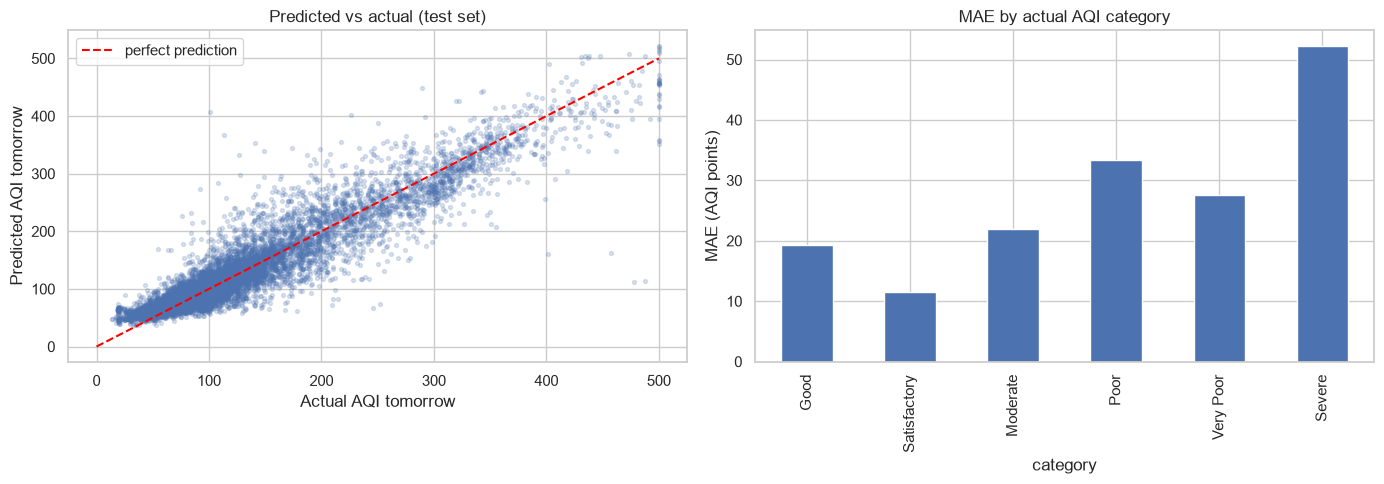

In [13]:
by_category = analysis.groupby("category", observed=True).agg(
    days=("abs_error", "size"),
    MAE=("abs_error", "mean"),
    bias=("error", "mean"),
).round(1)
print("Errors by actual AQI category (bias < 0 means the model predicts too low):")
print(by_category)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(analysis["actual"], analysis["predicted"], alpha=0.2, s=8)
axes[0].plot([0, 500], [0, 500], color="red", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual AQI tomorrow")
axes[0].set_ylabel("Predicted AQI tomorrow")
axes[0].set_title("Predicted vs actual (test set)")
axes[0].legend()
by_category["MAE"].plot(kind="bar", ax=axes[1], title="MAE by actual AQI category")
axes[1].set_ylabel("MAE (AQI points)")
plt.tight_layout()
plt.show()

**Insight:** This is the most important finding. The model is **pulled towards the middle**:
- It **over-predicts clean days**: Good days have a bias of +19.
- It **under-predicts the worst days**: Very Poor days have a bias of -13 and Severe days -37, with an MAE of 52.

The scatter plot shows the same thing: points at high actual AQI sit below the red line. Severe days are only about 3% of the data (see EDA section 8), so the model has few examples to learn them from. For a health app, this is the most costly kind of error, because people would be told the air is better than it is on the most dangerous days.

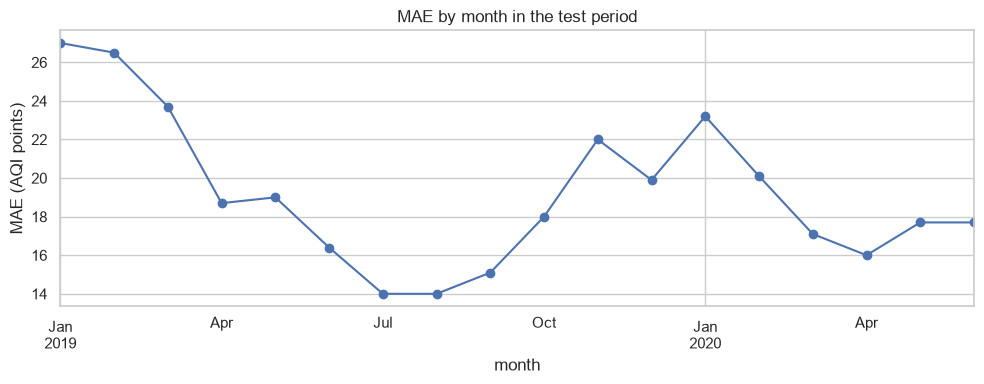

MAE in 2019: 19.4
MAE in 2020: 18.6

Ten largest errors:
     City       Date  actual  predicted  error
 Guwahati 2019-08-11   488.0      113.0 -375.0
 Amritsar 2020-06-02   478.0      112.0 -366.0
Ahmedabad 2020-06-03   101.0      407.0  306.0
   Jaipur 2019-04-07   457.0      162.0 -295.0
 Shillong 2019-09-04   113.0      367.0  254.0
  Talcher 2019-11-06   401.0      161.0 -240.0
 Guwahati 2019-08-13   141.0      353.0  212.0
  Chennai 2019-02-26   127.0      333.0  206.0
 Guwahati 2019-05-26   149.0      340.0  191.0
 Guwahati 2019-02-16    92.0      273.0  181.0


In [14]:
analysis["month"] = analysis["Date"].dt.to_period("M")
by_month = analysis.groupby("month")["abs_error"].mean().round(1)
by_month.plot(figsize=(10, 4), marker="o", title="MAE by month in the test period")
plt.ylabel("MAE (AQI points)")
plt.tight_layout()
plt.show()

print("MAE in 2019:", round(analysis.loc[analysis["Date"].dt.year == 2019, "abs_error"].mean(), 1))
print("MAE in 2020:", round(analysis.loc[analysis["Date"].dt.year == 2020, "abs_error"].mean(), 1))
print("\nTen largest errors:")
print(analysis.nlargest(10, "abs_error")[["City", "Date", "actual", "predicted", "error"]].round({"actual": 0, "predicted": 0, "error": 0}).to_string(index=False))

**Insight:** The error is similar in 2019 (19.4) and 2020 (18.6), so the model held up even during the COVID lockdown. It rises in winter months, as seen above. The ten largest errors are mostly **sudden spikes or drops** that today's readings cannot predict, for example Guwahati on 11 August 2019 (actual 488, predicted 113) and Amritsar on 2 June 2020 (actual 478, predicted 112). These look like one-day events (fires, dust storms, festivals) or sensor glitches. Several other big misses are in Guwahati, which suggests its readings are noisy.

**What would fix these errors:**
1. **Weather data** (wind speed, rainfall, temperature, humidity) to explain sudden build-ups and clean-ups.
2. **Lag features** such as today's AQI and the last 3 days' average. EDA showed today's AQI is the strongest single signal (correlation 0.91).
3. **Sample weights or a quantile/log-target model** to stop the model shrinking extreme days towards the middle.
4. **Per-city outlier checks**, for example for Guwahati, like the CO check done for Ahmedabad.

### 11.1 How sure is a single prediction?

**What and why:** the app should show a range, not just one number. We take the test-set errors and find the size that covers **80%** of them, overall and per predicted category. The app then says, for example, "121 (likely between 100 and 142)".

In [15]:
interval_80 = float(analysis["abs_error"].quantile(0.8))
analysis["pred_category"] = pd.cut(analysis["predicted"].clip(0, 500), bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True)
interval_by_category = analysis.groupby("pred_category", observed=True)["abs_error"].quantile(0.8).round(1)

print(f"80% of test forecasts were within ±{interval_80:.1f} AQI points")
print(interval_by_category)

80% of test forecasts were within ±28.0 AQI points
pred_category
Good            22.5
Satisfactory    19.9
Moderate        31.8
Poor            55.5
Very Poor       50.6
Severe          56.5
Name: abs_error, dtype: float64


**Insight:** Overall, 80% of test forecasts were within ±28 AQI points. The range depends on the forecast: about ±20 to 23 for Good and Satisfactory forecasts, but about ±51 to 57 for Poor, Very Poor and Severe. The app uses the category-specific range, so a high forecast honestly shows a wider "likely between" range.

## 12. Save the model and results for the app

**What and why:** we save:
- `best_model.pkl`: the whole **Pipeline** (imputer + model). The app only needs to build the 13 feature columns, and the Pipeline handles the rest.
- `fill_values.pkl`: training medians, used to pre-fill the app's form.
- `feature_cols.json`: the exact feature order.
- `metrics.json`: results, importance and error tables, shown on the app's Model Performance tab.

The chosen model is refitted on the full training set (it already was in section 9) before saving.

In [16]:
def to_dict(series):
    return {str(k): round(float(v), 3) for k, v in series.items()}

joblib.dump(best_model, MODEL_PATH)
joblib.dump(fill_values, FILL_VALUES_PATH)
with open(FEATURE_COLS_PATH, "w") as f:
    json.dump(FEATURE_COLS, f)

metrics = {
    "best_model": best_name,
    "best_params": {k: {p: (v if v is None or isinstance(v, (int, float, str)) else str(v)) for p, v in d.items()}
                    for k, d in best_params.items()},
    "train_period": [str(train["Date"].min().date()), str(train["Date"].max().date())],
    "test_period": [str(test["Date"].min().date()), str(test["Date"].max().date())],
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "cv_results": cv_df.round(3).to_dict(orient="records"),
    "test_results": test_df.drop(columns="MAE vs baseline").round(3).to_dict(orient="records"),
    "baseline_test_mae": round(float(baseline_mae), 3),
    "permutation_importance": to_dict(importance.sort_values(ascending=False)),
    "error_by_city": to_dict(by_city["mean"]),
    "error_by_season": to_dict(by_season),
    "error_by_category": {str(k): {"days": int(r["days"]), "MAE": float(r["MAE"]), "bias": float(r["bias"])}
                          for k, r in by_category.iterrows()},
    "interval_80": round(interval_80, 1),
    "interval_80_by_category": to_dict(interval_by_category),
}
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:", MODEL_PATH.name, FILL_VALUES_PATH.name, FEATURE_COLS_PATH.name, METRICS_PATH.name)

Saved: best_model.pkl fill_values.pkl feature_cols.json metrics.json


### 12.1 Check that the saved model loads and predicts

**What and why:** we reload the saved file and predict a few test rows, including one with a **missing** value, to prove the app will get the same results.

In [17]:
loaded = joblib.load(MODEL_PATH)
sample = X_test.head(3).copy()
sample.iloc[0, sample.columns.get_loc("NH3")] = np.nan   # the Pipeline fills this
print(pd.DataFrame({"actual": y_test.head(3).values,
                    "predicted": loaded.predict(sample).round(1)}))

   actual  predicted
0   210.0      183.9
1   176.0      200.0
2   103.0      124.6


**Insight:** The reloaded Pipeline predicts normally, even with a missing NH3 value, because the imputer inside it fills the gap with the training median.

## 13. Conclusion

**Summary:** a tuned **Gradient Boosting** Pipeline forecasts tomorrow's AQI with **MAE 19.1, RMSE 28.4 and R² 0.880** on unseen 2019-2020 data, a **77% lower error than the baseline** (MAE 82.2). It was chosen using 5-fold time-based cross-validation and hyperparameter search on 2015-2018 data only, so the test result is an honest estimate.

**Key findings**
- PM2.5, then PM10, drive almost all predictions; date features add little once pollutant readings are known.
- Errors are largest in winter and in polluted northern cities.
- The model under-predicts Severe days (bias -37) and over-predicts Good days (bias +19).

**Limitations**
- No weather data, which explains many sudden spikes and drops.
- Severe days are rare (3%), so they are predicted poorly.
- Ahmedabad lost most of its data to the copied-CO problem.
- The test period includes the unusual 2020 lockdown.
- Trained on 2015-2020 data, so it may drift on today's conditions.

**Next steps:** add weather and lag features (today's AQI, 3-day averages), try weighting rare severe days more, retrain on recent data, and deploy online.

## Viva preparation: likely questions and short answers

**Why this problem and dataset?** Air pollution is a major health problem in Indian cities, and a next-day forecast lets people act in advance. The Kaggle CPCB dataset is real, messy, multi-city data (29,531 rows, 26 cities), not a pre-cleaned toy dataset.

**Why predict tomorrow instead of today?** Today's AQI can be calculated directly from today's readings, so predicting it would be trivial. Tomorrow's AQI is what people need for planning, and it is a genuine forecast.

**How did you create the target?** By shifting each city's AQI back by one day, and setting the target to missing when the next row is not exactly one day later (`src/data.py`, `add_target`).

**How did you handle missing values?** With median imputation inside the Pipeline. The median resists extreme spikes, and inside a Pipeline it is learned only from the training data (or training fold), so there is no leakage. Rows without a target were dropped. Benzene, Toluene and Xylene were excluded because they are mostly missing and weakly related to AQI.

**How did you treat outliers?** Deliberately, not automatically. EDA showed that all of Ahmedabad's AQI values above 500 occur in rows where CO is a copy of NO, so those 1,317 rows were dropped. AQI was then capped at 500, the official scale maximum.

**How did you handle imbalance?** It is a regression task, but Severe days are only 3% of the data. I measured the effect in error analysis (Severe days are under-predicted by 37 points) instead of hiding it, and proposed sample weighting as a fix.

**How did you avoid data leakage?** By splitting by date before fitting anything, fitting the imputer and scaler only inside the Pipeline on training data, using time-based cross-validation (never training on the future), never using AQI_Bucket as an input, and touching the test set only once at the end.

**How did you avoid overfitting?** With cross-validation for model choice, tuned settings that limit complexity (shallow trees, minimum leaf sizes, slow learning rate, subsampling), and a final check on unseen years. The test ranking matches the cross-validated ranking.

**Why Gradient Boosting over the alternatives?** It had the lowest cross-validated MAE and the most stable folds. Linear Regression was 7 points worse on the test set because the relationships are non-linear. Random Forest was almost as good, so it is a reasonable alternative.

**Why MAE?** It is in AQI points and easy to explain to users, and it is robust to a few extreme days. RMSE and R² are reported too.

**Why TimeSeriesSplit instead of normal KFold?** Normal KFold shuffles dates, so the model would train on the future and validate on the past, which gives an over-optimistic score.

**What does the error analysis show?** Larger errors in winter and in polluted northern cities, over-prediction of clean days, and under-prediction of Severe days (bias -37). This is because Severe days are rare and the model has no weather data.

**What would you do with more time or data?** Add weather data and lag features (today's AQI was the strongest signal in EDA), weight rare severe days, use recent data, and deploy online.

**What went wrong and how did you debug it?** Extreme AQI values above 2,000 looked impossible. Comparing pollutants on extreme and normal days showed CO was unusually high in Ahmedabad. Checking NO against CO revealed CO was a copy of NO in 66% of Ahmedabad's rows, and all 412 extreme days were among them.

**What is permutation importance?** Shuffle one feature on the test set and measure how much the error increases. A large increase means the model relies on that feature.

**2-minute summary:** "I forecast tomorrow's AQI for 26 Indian cities so people can plan outdoor activity. Using 2015-2020 CPCB data, I found and removed faulty Ahmedabad CO readings, created a next-day target, and split by date to avoid leakage. I compared a baseline, Linear Regression, a Decision Tree, Random Forest and Gradient Boosting with time-based cross-validation and tuned the best ones. Tuned Gradient Boosting reached an MAE of 19 on 2019-2020, 77% better than the baseline. PM2.5 drives most predictions. The main weakness is under-predicting rare Severe days, which weather and lag features could fix. It is deployed as a Streamlit app with explanations for each prediction."